[Chapter 9](09_Correlations_AR.ipynb) built the tools for reading serial dependence, the ACF and the PACF, and the first model that exploits it: the **autoregressive (AR)** model, which regresses a series on its own past, with the number of lags read off the PACF.

Two questions were left open. Real series have trends and seasons, while AR models need stationary data: how do we forecast such a series with an AR model? And what if a series is better described by its past *shocks* than by its past values?

This chapter answers the first question with two recipes for making a series stationary and putting the trend and seasonality back afterwards. It answers the second with the **moving-average (MA)** model, the counterpart of the AR model.

# Learning objectives

By the end of this lecture you should be able to

1. forecast a series with trend and seasonality by making it stationary (differencing, or subtracting a Holt-Winters fit), fitting an AR or MA model to what is left, and **putting the trend and seasonality back**;
2. predict what differencing does to the correlograms (**over-differencing**), and explain why it makes order selection harder;
3. write down an **MA($q$)** model, explain why it is always stationary, and pass its coefficients to `statsmodels`;
4. identify the order of an MA model from the correlograms: the **ACF cuts off after lag $q$**, while the PACF tails off;
5. explain why the forecasts of stationary AR and MA models revert to the mean after a few steps, and what that means for the forecast horizon.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | `random.default_rng`, `diff`, `cumsum`, `convolve`, `polyfit` |
| `matplotlib.pyplot` | `subplots`, `plot`, `bar`, `fill_between` |
| `scipy.fft` | `fft`, inside the `fft_analysis` helper of Chapter 2 |
| `statsmodels.tsa.arima_process` | **`ArmaProcess`** -- simulate AR/MA processes, compute their *theoretical* ACF and PACF, and their $\psi$ weights (`arma2ma`) |
| `statsmodels.tsa.stattools` | `adfuller` |
| `statsmodels.graphics.tsaplots` | **`plot_acf`**, **`plot_pacf`** |
| `statsmodels.tsa.holtwinters` | `ExponentialSmoothing` (Holt-Winters, Chapter 6) |
| `statsmodels.tsa.arima.model` | **`ARIMA`** -- fit AR and MA models and forecast with them |

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft

from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

# Expected noise we do not want in the output:
#  - ARIMA warns when its optimizer stops before full convergence;
#  - statsmodels 0.15 announces a future change to the return type of adfuller.
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", FutureWarning)

rng = np.random.default_rng(8990)     # reproducibility: the same seed as Chapter 9

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4), the MSE (Chapter 6), the FFT period finder (Chapter 2), and the two correlogram helpers of Chapter 9. `theory_marks` marks theoretical correlations on a correlogram, and `correlograms` draws the ACF and PACF side by side, optionally with the theoretical values of an `ArmaProcess`.

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)


def fft_analysis(signal):
    "Dominant period of a signal, after removing a linear trend (Chapter 2)."
    # Linear detrending
    slope, intercept = np.polyfit(np.arange(len(signal)), signal, 1)
    trend = np.arange(len(signal)) * slope + intercept
    detrended = signal - trend

    fft_values = fft(detrended)
    frequencies = np.fft.fftfreq(len(fft_values))

    # Remove negative frequencies
    positive_frequencies = frequencies[frequencies > 0]
    magnitudes = np.abs(fft_values)[frequencies > 0]

    # Identify dominant frequency, and convert it to a period
    dominant_frequency = positive_frequencies[np.argmax(magnitudes)]
    print(f"Dominant Frequency: {dominant_frequency:.3f}")
    dominant_period = 1 / dominant_frequency
    print(f"Dominant Period: {dominant_period:.2f} time units")

    return dominant_period, positive_frequencies, magnitudes


def theory_marks(ax, values, label="theory"):
    "Mark theoretical correlations (lag 0, 1, 2, ...) on a correlogram."
    ax.plot(np.arange(len(values)), values, "_", color="red", ms=14, mew=2, label=label)
    ax.legend(loc="upper right", fontsize=8)


def correlograms(x, lags=20, process=None, title=""):
    "ACF and PACF side by side, optionally with the theoretical values of an ArmaProcess."
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    plot_acf(x, lags=lags, ax=axes[0], title=f"ACF {title}")
    plot_pacf(x, lags=lags, ax=axes[1], title=f"PACF {title}")
    if process is not None:
        theory_marks(axes[0], process.acf(lags + 1))
        theory_marks(axes[1], process.pacf(lags + 1))
    for ax in axes:
        ax.set_xlabel("lag k")
        ax.grid(alpha=0.3)
    fig.tight_layout()
    return axes

Two new ones save repetition below:

- `forecast_plot` draws training data, test data and a forecast on one time axis.
- `score_table` prints the test-set MSE of several forecasts, over the whole horizon and over its first few steps.

In [3]:
def forecast_plot(train, test, preds, title="", ax=None, figsize=(10, 3.5)):
    "Training data, held-out test data and a forecast on one time axis; MSE in the legend."
    t_train = np.arange(len(train))
    t_test = np.arange(len(train), len(train) + len(test))
    ax = run_sequence_plot(train, t_train, title=title, ax=ax, figsize=figsize, label="train")
    ax.plot(t_test, test, color="black", lw=1, label="test")
    ax.plot(t_test, preds, color="red", ls="--", lw=1.5, label=f"forecast (MSE = {mse(test, preds):.2f})")
    ax.legend(loc="upper left")
    return ax


def score_table(test, forecasts, h_short=3):
    "Test-set MSE of several forecasts, over all steps and over the first h_short steps."
    print(f"{'':34s}{f'MSE, all {len(test)} steps':>20s}{f'MSE, first {h_short} steps':>22s}")
    for name, preds in forecasts.items():
        preds = np.asarray(preds)
        print(f"{name:34s}{mse(test, preds):20.2f}{mse(test[:h_short], preds[:h_short]):22.2f}")

# The AR(2) process from Chapter 9

The AR examples below use the AR(2) process of [Chapter 9](09_Correlations_AR.ipynb#AR-model-identification),

$$x_t = 0.5\,x_{t-1} - 0.7\,x_{t-2} + \varepsilon_t ,$$

i.e., `ar = [1.0, -0.5, 0.7]` in the `statsmodels` convention. We rebuild exactly the same 200 points: same seed, and before simulating we draw and discard the 1,100 normal values that Chapter 9 spent on its earlier examples.

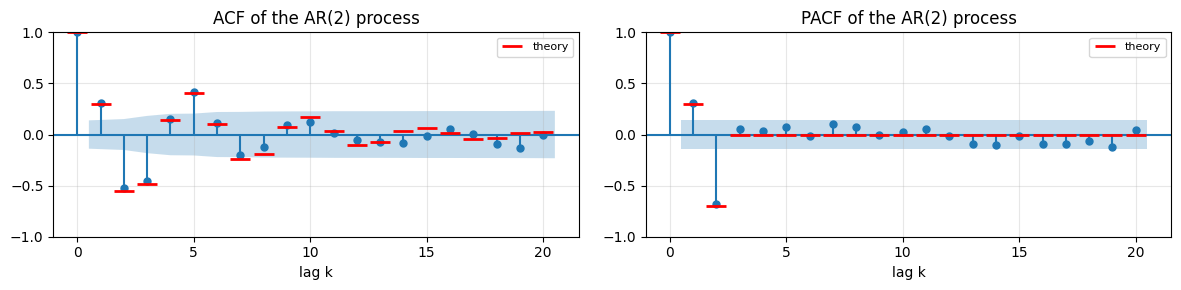

In [4]:
_ = rng.standard_normal(1100)      # the draws Chapter 9 made before simulating its AR(2) process

ar_process = ArmaProcess(ar=np.array([1.0, -0.5, 0.7]), ma=np.array([1.0]))
ar_data = ar_process.generate_sample(nsample=200, scale=1, burnin=1000, distrvs=rng.standard_normal)

correlograms(ar_data, lags=20, process=ar_process, title="of the AR(2) process")
plt.show()

Recall the identification rule of Chapter 9: in an AR($p$) the PACF **cuts off** after lag $p$ while the ACF tails off, so $p$ is the **last significant lag** of the PACF. Here the PACF has two significant lags, so $p = 2$.

---

# Forecasting with AR models

How do we forecast with an AR model? Real series usually have a trend and a seasonality, while an AR model can only be used on *stationary* data. We therefore proceed in three steps.

**Step 1: remove trend and seasonality.** Before an AR model can be applied, the series must be made stationary, with the techniques of the previous chapters. Two possible ways:

1. Apply first-order and seasonal differencing (Chapter 5). For seasonal period $L$,
$$
\begin{aligned}
\Delta x_t &= x_t - x_{t-1} && \text{removes the trend,}\\
R_t = \Delta_L \Delta x_t &= \Delta x_t - \Delta x_{t-L} && \text{removes the seasonality.}
\end{aligned}
$$
2. Estimate the trend $T_t$ and the seasonality $S_t$, e.g., with seasonal decomposition (Chapter 2) or a smoother (Chapter 6), and subtract them:
$$R_t = x_t - T_t - S_t .$$

**Step 2: apply the AR model.**

- Identify the order $p$ from the PACF of $R_t$.
- Fit an AR($p$) model to the detrended and deseasonalized series $R_t$.
- Forecast the next values $\hat R_{T+h}$, $h = 1, \dots, H$, where $H$ is the forecast horizon.

**Step 3: reconstruct the forecast.** How to do this depends on how the series was made stationary in step 1.

- If we **differenced**, we undo the differencing with cumulative sums (Chapter 5): first $\widehat{\Delta x}_{T+h} = \hat R_{T+h} + \widehat{\Delta x}_{T+h-L}$, where $\widehat{\Delta x}$ means the *observed* $\Delta x$ whenever its time index is still inside the sample; then $\hat x_{T+h} = x_T + \sum_{j=1}^{h} \widehat{\Delta x}_{T+j}$.
- If we **subtracted a fitted trend and seasonality**, then for each $h \in [1, H]$ we forecast the trend $\hat T_{T+h}$ and the seasonal component $\hat S_{T+h}$ with the same method, and add them back:
$$\hat x_{T+h} = \hat R_{T+h} + \hat T_{T+h} + \hat S_{T+h} .$$

## Example: forecasting with an AR model

We build a series with a known structure: a linear trend, a seasonality of period $L = 12$, and the AR(2) process from above as the stochastic part.

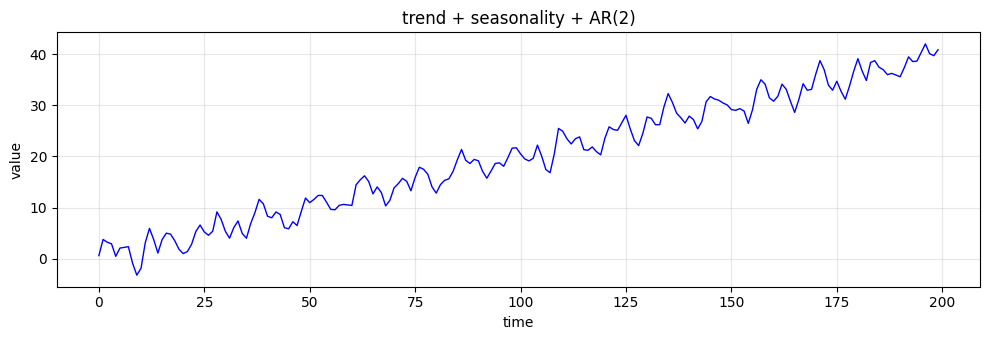

In [5]:
time = np.arange(200)
trend = 0.2 * time
seasonality = 2 * np.sin(2 * np.pi * time / 12)     # seasonal period L = 12
time_series_ar = trend + seasonality + ar_data

run_sequence_plot(time_series_ar, time, title="trend + seasonality + AR(2)", figsize=(10, 3.5))
plt.tight_layout(); plt.show()

Since we are going to compute forecasts, we split the data into a training set and a test set. The last 36 points, three seasonal cycles, are held out.

In [6]:
n_train = 164
train_data_ar = time_series_ar[:n_train]
test_data_ar = time_series_ar[n_train:]
print(f"train: {len(train_data_ar)} points,  test: {len(test_data_ar)} points")

train: 164 points,  test: 36 points


To determine the order $p$ we look at the PACF: by the rule above, $p$ is the **last significant lag**.

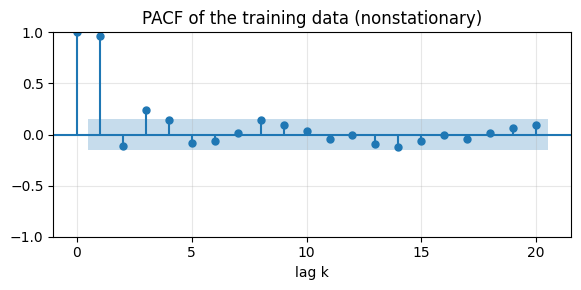

In [7]:
_, ax = plt.subplots(figsize=(6, 3))
plot_pacf(train_data_ar, lags=20, ax=ax, title="PACF of the training data (nonstationary)")
ax.set_xlabel("lag k"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Taken at face value, this PACF suggests $p = 1$: one huge spike at lag 1, close to 1. But the PACF **makes little sense** here. As discussed in Chapter 9, both ACF and PACF must be computed on stationary data. If the data are stationary, correlations drop quickly; if they do not, that is a sign of nonstationarity. A lag-1 partial autocorrelation near 1 is the trend talking, not the AR(2).

We built the series by hand, so we know it has a trend and a seasonality and is therefore not stationary. To be rigorous, we still test it with the Augmented Dickey-Fuller (ADF) test of Chapter 5.

In [8]:
_, pvalue, _, _, _, _ = adfuller(train_data_ar)
print(f"ADF p-value: {pvalue:.3f}")

ADF p-value: 0.930


Such a high $p$-value means that we **fail to reject** the null hypothesis

$$H_0: \text{the series has a unit root (it is nonstationary)}.$$

No surprises here. To make the data stationary we use one of the two techniques of Step 1, starting with differencing.

### Stationarity through differencing

We first apply a first-order difference to remove the trend, and check the result with the ADF test.

In [9]:
diff_ar = np.diff(train_data_ar)          # = train_data_ar[1:] - train_data_ar[:-1]

_, pvalue, _, _, _, _ = adfuller(diff_ar)
print(f"ADF p-value after first differencing: {pvalue:.3f}")

ADF p-value after first differencing: 0.000


The ADF test now indicates a stationary series. We could also apply *seasonal differencing* to remove the seasonal component. But differencing too many times can damage the structure of the data, a problem called **over-differencing** (Chapter 5). See [this explanation](https://people.duke.edu/~rnau/411arim2.htm) of how to choose the order of differencing.

Here is the series before and after first-order differencing.

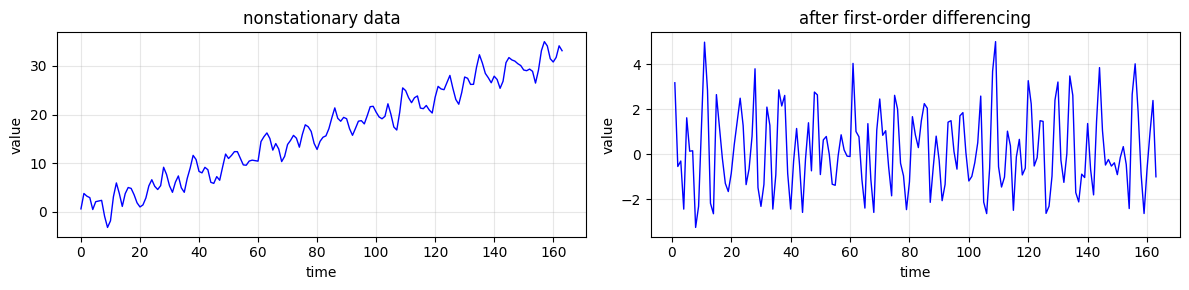

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
run_sequence_plot(train_data_ar, time[:n_train], title="nonstationary data", ax=axes[0])
run_sequence_plot(diff_ar, time[1:n_train], title="after first-order differencing", ax=axes[1])
plt.tight_layout(); plt.show()

We recompute the PACF on the differenced data, and compare it with the PACF of the AR(2) component alone (`ar_data`, which in practice we would not have) and of the nonstationary training data.

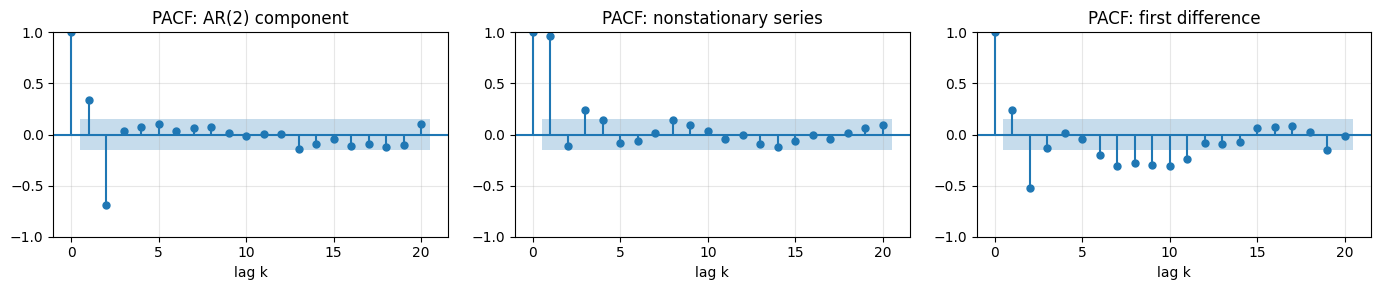

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
plot_pacf(ar_data[:n_train], lags=20, ax=axes[0], title="PACF: AR(2) component")
plot_pacf(train_data_ar, lags=20, ax=axes[1], title="PACF: nonstationary series")
plot_pacf(diff_ar, lags=20, ax=axes[2], title="PACF: first difference")
for ax in axes:
    ax.set_xlabel("lag k"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

- The prominent **negative spike at lag 2** appears both in the PACF of the AR(2) component and in that of the differenced series. These two look far more alike than the PACF of the nonstationary data did.
- The spike at lag 2 suggests $p = 2$, i.e., an AR(2) model.

> **Attention.** The differenced series also has significant spikes at higher lags (about 6 to 11) that are not in the AR(2) component. They are the **seasonal component left in the data**: the first difference of a period-12 sinusoid is another period-12 sinusoid, here of amplitude $2 \cdot 2\sin(\pi/12) \approx 1$. Let us see whether seasonal differencing removes them, and recompute the PACF.

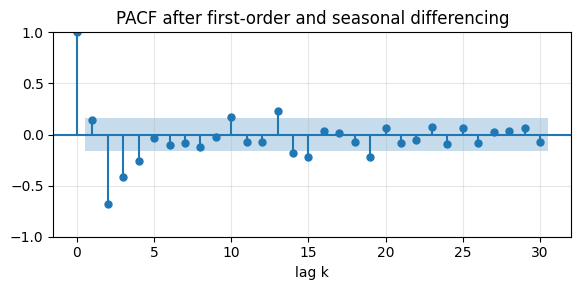

In [12]:
diff_diff_ar = diff_ar[12:] - diff_ar[:-12]       # seasonal difference, L = 12

_, ax = plt.subplots(figsize=(6, 3))
plot_pacf(diff_diff_ar, lags=30, ax=ax, title="PACF after first-order and seasonal differencing")
ax.set_xlabel("lag k"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The seasonal spikes at lags 6 to 11 are gone. But the PACF of the AR(2) component is **not** recovered. Lag 2 still stands out, but lags 3 and 4 are now significant too, and new spikes appear around lag 13. If anything, this PACF looks even more different from the original one.

This is the general experience: after differencing it is rare to get a "clean" PACF with only the prominent lags of the correct order. Interpreting the PACF (and ACF) to select the order of a model takes skill and experience. See [this guide](https://people.duke.edu/~rnau/411arim3.htm) for selecting the AR (and MA) order.

Are the extra spikes sampling noise? No, and here we can prove it. Each difference is a **linear filter**: $\Delta x_t = (1 - B)\,x_t$ and $\Delta_{12} x_t = (1 - B^{12})\,x_t$. Our trend is linear and our season has period exactly 12, so the two differences remove them *exactly*. What is left is the AR(2) component passed through both filters,

$$\Delta_{12}\Delta x_t = (1 - B)(1 - B^{12})\,\big[\text{AR(2) component}\big]_t ,$$

an ARMA process whose MA polynomial is $(1-B)(1-B^{12})$. Its theoretical PACF can be computed with `ArmaProcess`, as in the next cell.

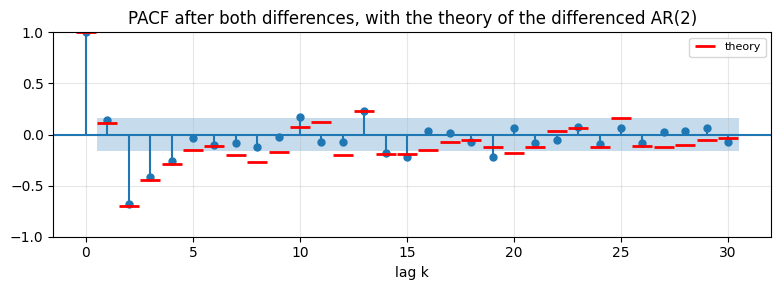

In [13]:
# Both differences are linear filters, and multiplying lag polynomials composes them:
#   (1 - B)(1 - B^12) applied to an AR(2) gives an ARMA(2, 13) whose MA part has unit roots.
first_diff = np.array([1.0, -1.0])
seasonal_diff = np.r_[1.0, np.zeros(11), -1.0]
ma_from_differencing = np.convolve(first_diff, seasonal_diff)

over_differenced = ArmaProcess(ar=[1.0, -0.5, 0.7], ma=ma_from_differencing)

_, ax = plt.subplots(figsize=(8, 3))
plot_pacf(diff_diff_ar, lags=30, ax=ax, title="PACF after both differences, with the theory of the differenced AR(2)")
theory_marks(ax, over_differenced.pacf(31))
ax.set_xlabel("lag k"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The red theoretical marks reproduce every major feature of the sample PACF: $-0.7$ at lag 2, the negative tail at lags 3 and 4, and the bump at lag 13. The "dirty" PACF is not noise. It is exactly what $(1-B)(1-B^{12})$ does to an AR(2).

That is **over-differencing**. The trend and the season were deterministic, so subtracting them would have been enough. Differencing removed them, but it also filtered the stationary *noise*, which needed no filtering. The extra factors $(1-B)$ and $(1-B^{12})$ have roots on the unit circle, and they smear the two clean AR lags over many lags.

> **Note.** Over-differencing is not the only problem with achieving stationarity by differencing.
>
> - Data are lost at the beginning of the series: first-order plus seasonal differencing loses $L + 1$ observations.
> - It is easy to make **mistakes** when reverting the differencing to make predictions.
> - Reverting is harder still when there is a gap between the training and test sets, or when the forecast horizon $H$ is longer than the seasonal period $L$.

> **Note.** Should seasonal or first-order differencing come first? Mathematically, both orders give the same result, because the two filters commute: $(1-B)(1-B^L) = (1-B^L)(1-B)$. In practice, seasonal differencing is usually done first, because it is often enough on its own to make the data (almost) stationary. We want to difference as little as possible, to avoid over-differencing.

### Stationarity by subtracting the estimated trend and seasonality

As an alternative, we estimate the trend and seasonality with **triple exponential smoothing** (TES, Holt-Winters, Chapter 6), and compute the residuals by subtracting the estimated trend and seasonality.

One subtlety: `fittedvalues` are TES's **one-step-ahead** predictions, so the residuals are one-step forecast errors. If the level smoothing parameter $\alpha$ is small, the fitted level barely follows the noise and the residuals are close to the stochastic component. If $\alpha$ is large, the level chases the noise and the residuals start to look like a differenced series.

alpha = 0.000,  beta = 0.000,  gamma = 0.000


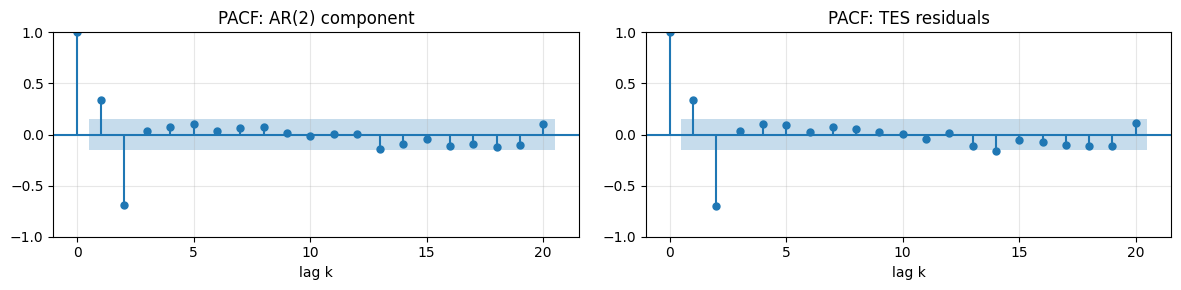

In [14]:
tes = ExponentialSmoothing(train_data_ar, trend="add",
                           seasonal="add", seasonal_periods=12).fit()
trend_and_seasonality = tes.fittedvalues          # estimated trend + seasonality
tes_resid = train_data_ar - trend_and_seasonality

print(f"alpha = {tes.params['smoothing_level']:.3f},  beta = {tes.params['smoothing_trend']:.3f},  "
      f"gamma = {tes.params['smoothing_seasonal']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
plot_pacf(ar_data[:n_train], lags=20, ax=axes[0], title="PACF: AR(2) component")
plot_pacf(tes_resid, lags=20, ax=axes[1], title="PACF: TES residuals")
for ax in axes:
    ax.set_xlabel("lag k"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

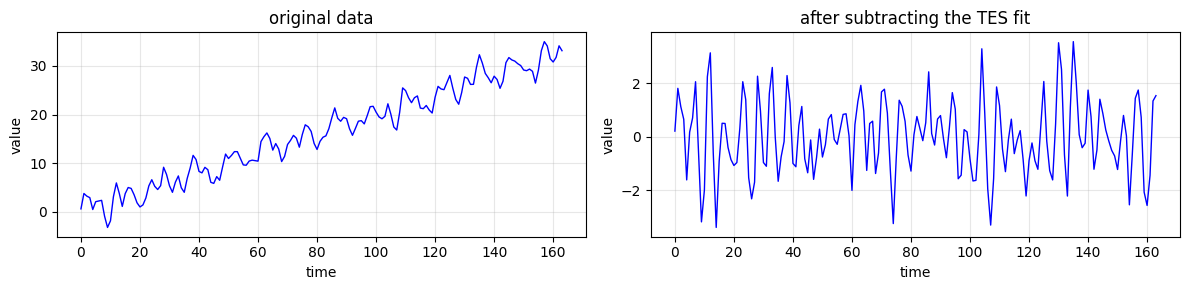

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
run_sequence_plot(train_data_ar, time[:n_train], title="original data", ax=axes[0])
run_sequence_plot(tes_resid, time[:n_train], title="after subtracting the TES fit", ax=axes[1])
plt.tight_layout(); plt.show()

The optimizer chose $\alpha = \beta = \gamma = 0$: the level, slope and seasonal pattern are estimated once and never updated. That is exactly right for this toy series, whose trend and seasonality are deterministic. It is also why the TES residuals are almost exactly the AR(2) component: their PACF is a near copy of the original one, and points cleanly to $p = 2$.

> **Tip.** Here we knew the main period to be 12. In general we must estimate it, for example with the `fft_analysis` function of Chapter 2. We apply it to the **training** data only: the test set plays the role of the future, so we must not look at it.

In [16]:
period, _, _ = fft_analysis(train_data_ar)
print(f"Period: {np.round(period)}")

Dominant Frequency: 0.085
Dominant Period: 11.71 time units
Period: 12.0


> **Attention.** Smoothers work so well here because this is toy data: additive components, a linear trend, constant variance. Many real-world series are less tidy. Then we may have to fall back on other techniques, including differencing and the "dirty" correlograms that come with it.

Once the data are stationary we can fit the AR(2) model and forecast. How we reconstruct the forecast depends on how we obtained the stationary data. We start with the differenced data.

### Predictions with the differencing approach

We fit an AR(2) model to `diff_diff_ar` and forecast as many steps as there are test points. `ARIMA(..., order=(p, 0, 0))` is an AR($p$) model with a constant; the middle 0 means "no differencing inside the model", since we did it by hand. Besides the point forecast, `get_forecast` returns a 95% prediction interval.

[ 1.000e-03  2.430e-01 -7.010e-01  2.828e+00]


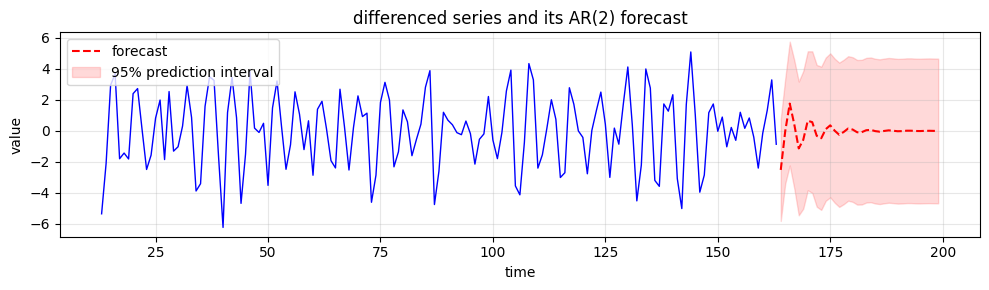

In [17]:
model = ARIMA(diff_diff_ar, order=(2, 0, 0))
model_fit = model.fit()
print(model_fit.params.round(3))          # [const, ar.L1, ar.L2, sigma2], in the signs of the model equation

fc = model_fit.get_forecast(steps=len(test_data_ar))
diff_preds = fc.predicted_mean
diff_ci = fc.conf_int(alpha=0.05)

t_dd = time[13:n_train]                    # first-order + seasonal differencing loses L + 1 = 13 points
t_test = time[n_train:]
ax = run_sequence_plot(diff_diff_ar, t_dd, title="differenced series and its AR(2) forecast", figsize=(10, 3))
ax.plot(t_test, diff_preds, color="red", ls="--", lw=1.5, label="forecast")
ax.fill_between(t_test, diff_ci[:, 0], diff_ci[:, 1], color="red", alpha=0.15, label="95% prediction interval")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

The fitted coefficients, $\hat\phi_1 \approx 0.24$ and $\hat\phi_2 \approx -0.70$, are not the $(0.5, -0.7)$ we simulated, and the noise variance is about 2.8 instead of 1. An AR(2) is being asked to describe the over-differenced process above, and it does so as best it can.

After only a few steps the forecast settles at the mean, and the prediction interval stops widening. This is how a stationary AR model *always* forecasts. The influence of the last observed values dies out geometrically: after $h$ steps it is multiplied by roughly $|\text{root}|^{-h}$. Beyond a few steps the best the model can say is "the mean, give or take the natural spread of the series". The model is not failing here. The far future is simply not predictable from the recent past of a stationary process.

To obtain the final predictions we must revert the seasonal differencing first, then the first-order differencing.

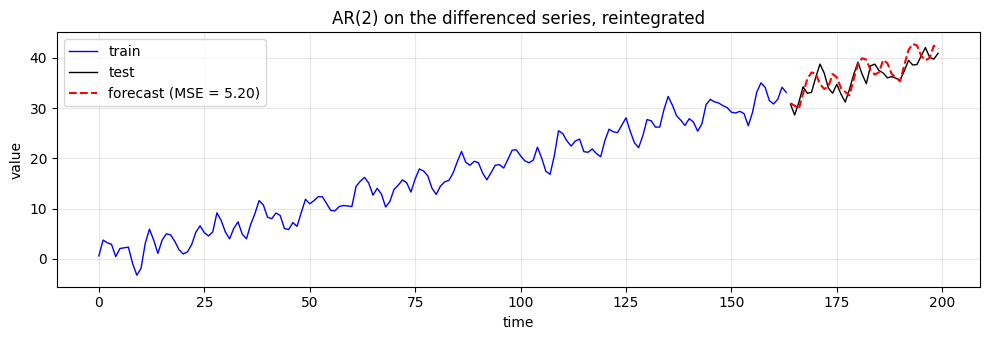

In [18]:
# Reintegrating the seasonal differencing: Delta x_{T+h} = R_{T+h} + Delta x_{T+h-12}
reintegrated_seasonal = np.zeros(len(test_data_ar))
reintegrated_seasonal[:12] = diff_ar[-12:] + diff_preds[:12]          # Delta x_{T+h-12} still observed
for i in range(12, len(test_data_ar)):
    reintegrated_seasonal[i] = reintegrated_seasonal[i - 12] + diff_preds[i]   # ... or itself a forecast

# Reintegrating the first-order differencing: x_{T+h} = x_T + cumulative sum of Delta x
reintegrated = reintegrated_seasonal.cumsum() + train_data_ar[-1]

forecast_plot(train_data_ar, test_data_ar, reintegrated, title="AR(2) on the differenced series, reintegrated")
plt.tight_layout(); plt.show()

> **Caution.** It is very easy to make errors with indices when reverting differencing operations. The code above also assumes that there is no gap between the training and the test data.

A good way to catch such errors is to let `statsmodels` do the bookkeeping. If the differencing is given to `ARIMA` itself, through `order=(p, d, q)` and `seasonal_order=(P, D, Q, L)`, the model differences internally and returns forecasts **on the original scale**. This is a preview of seasonal ARIMA, the subject of the next chapter. Here we ask for $d = 1$ and $D = 1$ with $L = 12$, and nothing else seasonal.

In [19]:
sarima = ARIMA(train_data_ar, order=(2, 1, 0), seasonal_order=(0, 1, 0, 12)).fit()
sarima_preds = sarima.forecast(len(test_data_ar))

print(f"largest difference from the hand-made reintegration: {np.max(np.abs(sarima_preds - reintegrated)):.3f}")
print(f"MSE, by hand    : {mse(test_data_ar, reintegrated):.3f}")
print(f"MSE, statsmodels: {mse(test_data_ar, sarima_preds):.3f}")

largest difference from the hand-made reintegration: 0.077
MSE, by hand    : 5.201
MSE, statsmodels: 5.140


The two forecasts agree to within 0.08 at every step, so the hand-made reintegration is correct. The small differences come from estimation, not bookkeeping: our hand fit includes a constant, and `ARIMA` handles the first $L + 1$ observations inside its likelihood instead of discarding them.

Look again at the reintegrated forecast above: it **repeats the wiggles of the last observed season**. Reverting the seasonal difference sets $\widehat{\Delta x}_{T+h} = \hat R_{T+h} + \Delta x_{T+h-12}$, which copies the last 12 observed changes, *noise included*, into every future season. The differencing approach mistakes last year's random fluctuations for the seasonal pattern.

### Predictions with the TES-based approach

Next we use the stationary data obtained by subtracting the TES estimate of trend and seasonality. This time we fit the AR(2) model to `tes_resid` and forecast.

[-0.013  0.579 -0.7    0.867]


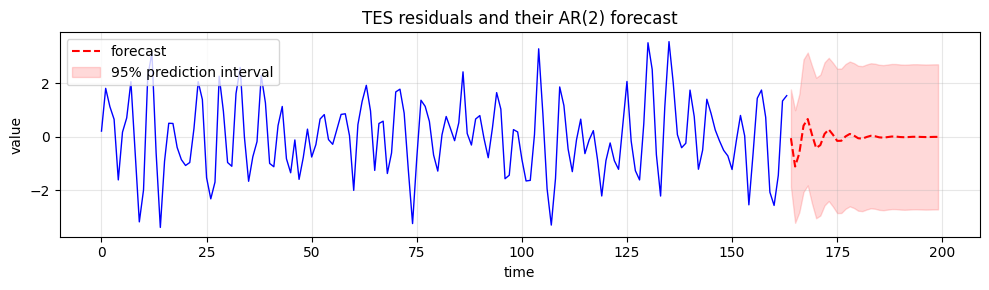

In [20]:
model = ARIMA(tes_resid, order=(2, 0, 0))
model_fit = model.fit()
print(model_fit.params.round(3))

fc = model_fit.get_forecast(steps=len(test_data_ar))
resid_preds = fc.predicted_mean
resid_ci = fc.conf_int(alpha=0.05)

ax = run_sequence_plot(tes_resid, time[:n_train], title="TES residuals and their AR(2) forecast", figsize=(10, 3))
ax.plot(t_test, resid_preds, color="red", ls="--", lw=1.5, label="forecast")
ax.fill_between(t_test, resid_ci[:, 0], resid_ci[:, 1], color="red", alpha=0.15, label="95% prediction interval")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Then we add the trend and the seasonality back. TES forecasts them for us, and the final forecast is the sum of the two predictions.

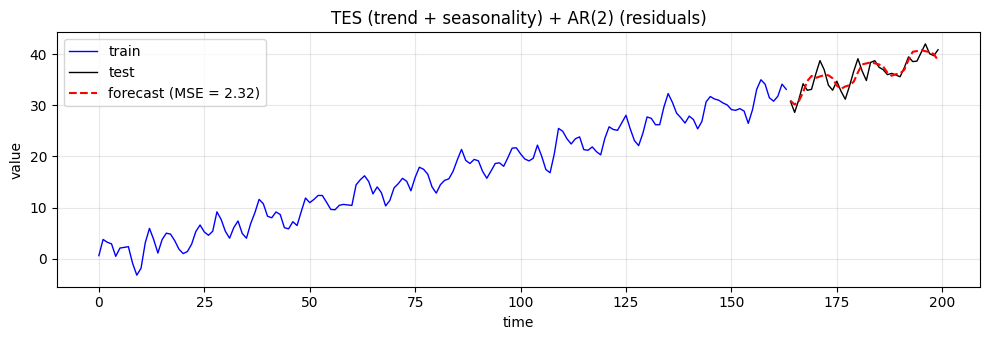

In [21]:
tes_pred = tes.forecast(len(test_data_ar))       # trend + seasonality, extrapolated
final_preds = tes_pred + resid_preds

forecast_plot(train_data_ar, test_data_ar, final_preds, title="TES (trend + seasonality) + AR(2) (residuals)")
plt.tight_layout(); plt.show()

We quantify the difference between the two approaches with the MSE on the test set. For reference we include TES alone, without the AR model, and an oracle that knows the true trend and seasonality, i.e. the best any method could do without forecasting the noise.

In [22]:
score_table(test_data_ar, {
    "differencing + AR(2)":             reintegrated,
    "TES + AR(2)":                      final_preds,
    "TES alone":                        tes_pred,
    "oracle: true trend + seasonality": trend[n_train:] + seasonality[n_train:],
})

                                     MSE, all 36 steps    MSE, first 3 steps
differencing + AR(2)                              5.20                  1.75
TES + AR(2)                                       2.32                  0.83
TES alone                                         2.34                  2.39
oracle: true trend + seasonality                  1.92                  1.96


Reading the table:

- **TES + AR(2)** beats the differencing approach by a wide margin (2.32 vs 5.20), and is not far from the oracle (1.92). The oracle knows the true trend and seasonality, so it is left only with the unpredictable AR(2) noise.
- But over all 36 steps, **TES alone** does almost as well as TES + AR(2) (2.34 vs 2.32). The AR model only matters for the first few steps, before its forecast decays to the mean. Over the first three steps the gain is large: 0.83 vs 2.39. There it even beats the oracle (1.96), which knows the trend and seasonality but cannot forecast the noise. For a few steps, the AR model can.

The second point holds in general, not just for this sample. Write the AR(2) as an infinite moving average of its shocks, $x_t = \sum_{j \ge 0} \psi_j \varepsilon_{t-j}$; `arma2ma` computes the weights $\psi_j$. An $h$-step forecast made at time $T$ knows every shock up to $T$, and has to set the $h$ future shocks $\varepsilon_{T+1}, \dots, \varepsilon_{T+h}$ to zero. Its error variance is therefore

$$\mathrm{Var}(x_{T+h} - \hat x_{T+h}) = \sigma^2\big(1 + \psi_1^2 + \dots + \psi_{h-1}^2\big),$$

which starts at $\sigma^2$ and climbs to $\mathrm{Var}(x_t)$, the error of simply forecasting the mean.

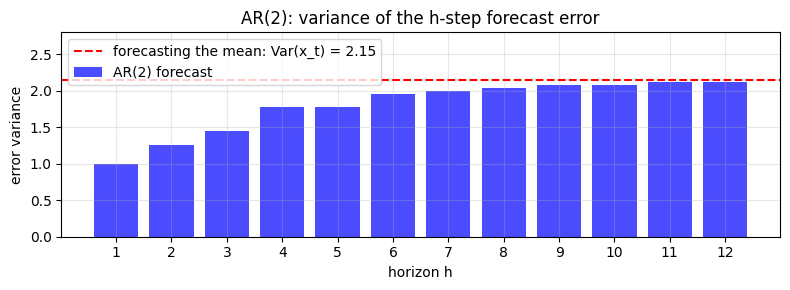

In [23]:
H = 12
psi = ar_process.arma2ma(H)                 # psi_0 = 1, psi_1, ..., psi_{H-1}
err_var = np.cumsum(psi ** 2)               # h-step forecast error variance, with sigma^2 = 1
var_x = ar_process.acovf(1)[0]              # Var(x_t): the error of forecasting the mean

_, ax = plt.subplots(figsize=(8, 3))
ax.bar(np.arange(1, H + 1), err_var, color="blue", alpha=0.7, label="AR(2) forecast")
ax.axhline(var_x, color="red", ls="--", label=f"forecasting the mean: Var(x_t) = {var_x:.2f}")
ax.set(title="AR(2): variance of the h-step forecast error", xlabel="horizon h", ylabel="error variance",
       xticks=range(1, H + 1), ylim=(0, 2.8))
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

At $h = 1$ the AR model cuts the error variance by more than half (1.00 vs 2.15). By $h = 4$ two thirds of that advantage is gone, and beyond about 8 steps it is negligible. **The AR part is a short-range forecaster.** It is valuable for the next few steps, and worthless at a horizon of three seasons, where the trend and seasonality do all the work. For a sensor sampled every second that may be exactly what is needed; for a quarterly plan it is not.

---

# Moving-average (MA) models

Another approach to modelling univariate time series is the **moving-average (MA)** model. The MA model is a linear regression of the current value of the series against the **current and past white-noise shocks**. The shocks are assumed to come from a distribution with mean 0 and constant variance $\sigma^2$, usually normal.

The MA model of order $q$, MA($q$), is

$$x_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \theta_2 \varepsilon_{t-2} + \dots + \theta_q \varepsilon_{t-q},$$

where

- $x_t$ is the value of the series at time $t$;
- $\mu$ is the mean of the series;
- $\theta_1, \dots, \theta_q$ are the coefficients of the model;
- $q$ is the order of the model, the number of lagged error terms;
- $\varepsilon_t$ is the white-noise error term at time $t$.

What follows from the definition:

- A shock affects the series for **exactly $q$ steps** and is then forgotten completely. In an AR model a shock decays geometrically but never fully disappears.
- An MA($q$) process is a finite weighted sum of white-noise terms, so it is **always stationary**, whatever the $\theta$'s. As with AR models, the *data* must be stationary before an MA model is fitted: stationary behavior is all an MA model can represent.
- Fitting is **more complicated** than for AR models, because the shocks are not observed. They have to be reconstructed recursively from the data for each trial value of $\theta$, so estimation needs **iterative nonlinear** optimization (maximum likelihood) instead of a single least-squares regression.
- MA models are **less interpretable** than AR models.
- We usually require the MA model to be **invertible**: all roots of $1 + \theta_1 z + \dots + \theta_q z^q$ outside the unit circle ($|\theta_1| < 1$ for MA(1)). An invertible MA($q$) can be rewritten as an AR($\infty$), which is why its PACF never cuts off (see below).

In `statsmodels`, the MA polynomial is passed **with its signs as they are**: `ma = [1, theta_1, ..., theta_q]`. (The AR signs, recall from Chapter 9, are flipped.)

> **Attention.** In [Chapter 6](06_Smoothing.ipynb) we smoothed series with moving averages. MA *models* are **not** the same thing. A moving-average smoother averages past **observations** with fixed weights to estimate a pattern. An MA model is a stochastic model in which the observation is a weighted sum of unobserved **shocks**. Each serves a different, important purpose; do not confuse the two.

## MA model identification

For [AR model identification](09_Correlations_AR.ipynb#AR-model-identification) in Chapter 9 we chose $p$ as the lag after which the PACF spikes become nonsignificant. For the order $q$ of an MA model we do the same with the **ACF**. In an MA($q$), $x_t$ and $x_{t-k}$ share a shock only when $k \le q$; beyond that they have nothing in common, so

$$\rho(k) = 0 \quad \text{for } k > q .$$

The **ACF cuts off** after lag $q$. As an example, we generate data from an MA(2) process with $\theta_1 = 0.7$ and $\theta_2 = 0.8$, i.e. `ma = [1.0, 0.7, 0.8]`. Again, the leading `1.0` is the zero lag.

invertible: True


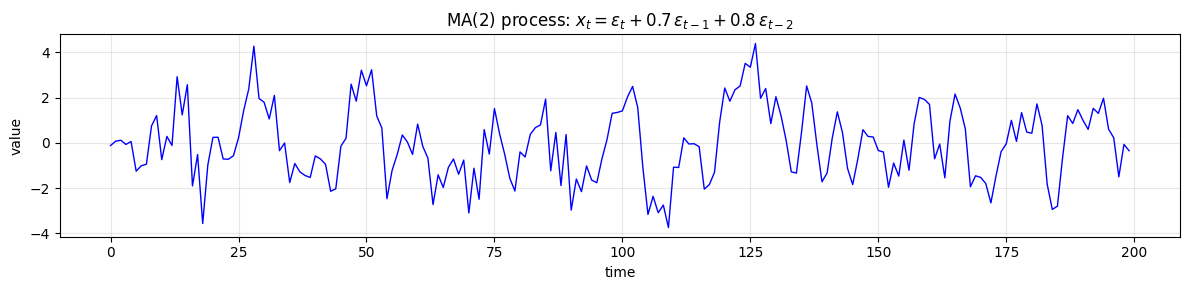

In [24]:
ma_process = ArmaProcess(ar=np.array([1.0]), ma=np.array([1.0, 0.7, 0.8]))
print(f"invertible: {ma_process.isinvertible}")

ma_data = ma_process.generate_sample(nsample=len(time), scale=1, burnin=1000, distrvs=rng.standard_normal)

run_sequence_plot(ma_data, title=r"MA(2) process: $x_t = \varepsilon_t + 0.7\,\varepsilon_{t-1} + 0.8\,\varepsilon_{t-2}$", figsize=(12, 3))
plt.tight_layout(); plt.show()

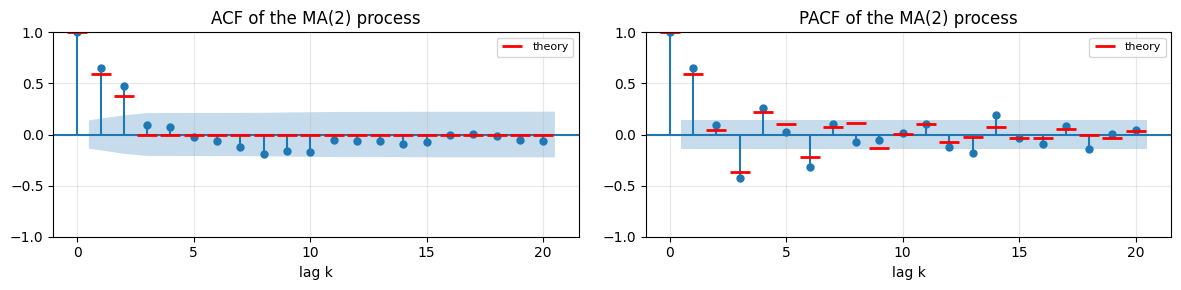

In [25]:
correlograms(ma_data, lags=20, process=ma_process, title="of the MA(2) process")
plt.show()

- As expected, the ACF **cuts off after lag 2**. The sample values 0.65 and 0.48 scatter around the theoretical $\rho(1) = (\theta_1 + \theta_1\theta_2)/(1+\theta_1^2+\theta_2^2) \approx 0.59$ and $\rho(2) = \theta_2/(1+\theta_1^2+\theta_2^2) \approx 0.38$, and everything beyond lag 2 is inside the band. This indicates an MA model of order $q = 2$.
- The PACF shows the pattern characteristic of an MA process: **slowly decaying spikes of alternating sign**. This is complementary to what we saw for the [AR process](09_Correlations_AR.ipynb#AR-model-identification) in Chapter 9. For MA, the ACF cuts off and the PACF tails off; for AR it is the other way round.

> **Try it yourself**
>
> - Change the `ma` coefficients of `ArmaProcess` above: modify, add or remove values.
> - Then see how the ACF changes. What happens to the PACF when $\theta_1$ is negative?

## Example: forecasting with an MA model

We repeat the procedure of the [AR example](#Example:-forecasting-with-an-AR-model) with an MA model. The only difference is that the stochastic part of the series is now the MA(2) process instead of the AR(2) one; the trend and the seasonality are the same.

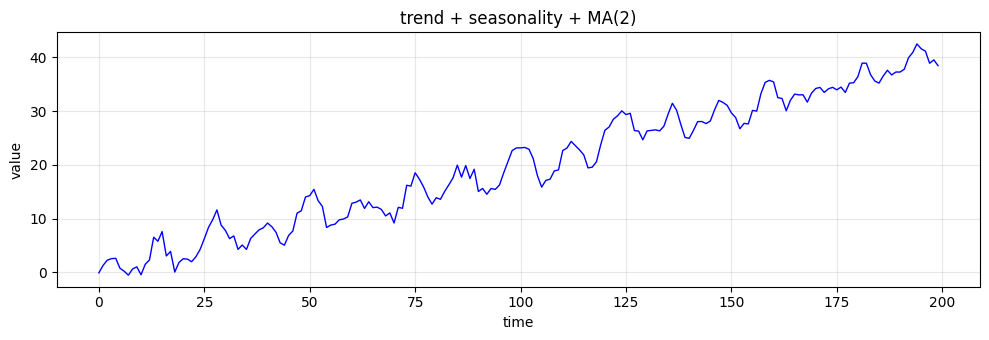

In [26]:
time_series_ma = trend + seasonality + ma_data

run_sequence_plot(time_series_ma, time, title="trend + seasonality + MA(2)", figsize=(10, 3.5))
plt.tight_layout(); plt.show()

In [27]:
# Train/test split
train_data_ma = time_series_ma[:n_train]
test_data_ma = time_series_ma[n_train:]

To identify the order $q$ we look at the ACF. The ACF of `train_data_ma` looks nothing like the [ACF of the MA process](#MA-model-identification) we saw above:

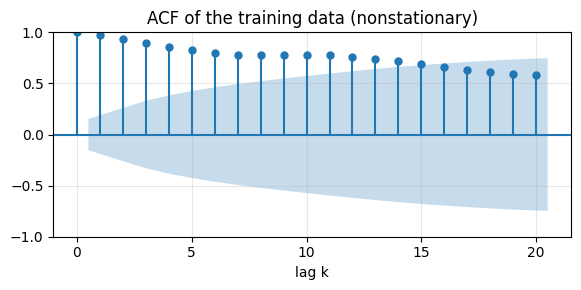

In [28]:
_, ax = plt.subplots(figsize=(6, 3))
plot_acf(train_data_ma, lags=20, ax=ax, title="ACF of the training data (nonstationary)")
ax.set_xlabel("lag k"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The slow decay is the trend again. As in the AR case, we need a stationary series both to read the ACF meaningfully and to estimate the MA coefficients correctly.

### Stationarity through differencing

As in the AR example, we first try to obtain stationarity by differencing, and check the result with the ADF test before and after.

In [29]:
diff_ma = np.diff(train_data_ma)

_, pvalue_ts, _, _, _, _ = adfuller(train_data_ma)
_, pvalue_diff, _, _, _, _ = adfuller(diff_ma)
print(f"ADF p-value (original series):    {pvalue_ts:.3f}")
print(f"ADF p-value (differenced series): {pvalue_diff:.3f}")

ADF p-value (original series):    0.951
ADF p-value (differenced series): 0.000


We also plot the differenced data and its ACF.

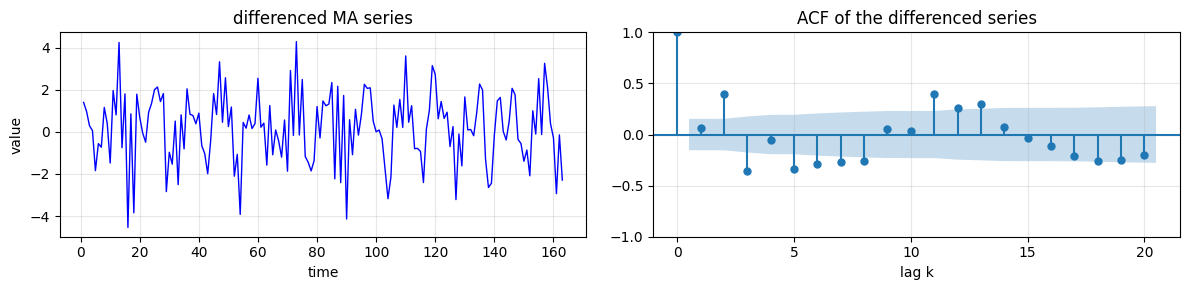

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
run_sequence_plot(diff_ma, time[1:n_train], title="differenced MA series", ax=axes[0])
plot_acf(diff_ma, lags=20, ax=axes[1], title="ACF of the differenced series")
axes[1].set_xlabel("lag k"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

As in the AR case, there are significant correlations at higher lags (negative at about 5 to 8, positive at 11 to 13). They are the seasonal component that the first difference leaves behind. The short lags are hard to read too: lag 1 is not significant, lag 2 is positive, lag 3 negative. Taken at face value, this ACF would suggest $q = 2$ or $q = 3$.

For comparison, we compute the ACF of

- the MA(2) component alone,
- the series after first-order differencing,
- the series after both first-order and seasonal differencing,

and mark on the last panel the theoretical ACF of the MA(2) filtered by $(1-B)(1-B^{12})$. After both differences the trend and the seasonality are gone **exactly**, so the doubly differenced series *is* the filtered MA(2), and its theory is known.

first-differenced MA(2) = MA(3) with coefficients [ 1.  -0.3  0.1 -0.8]


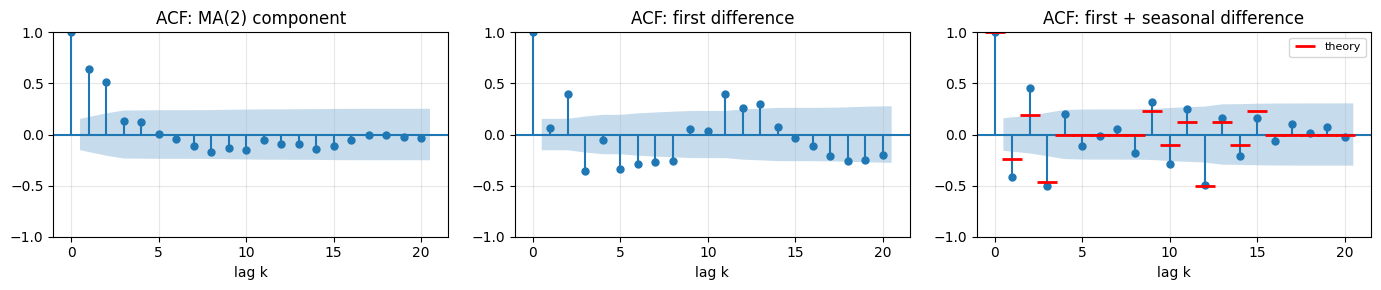

In [31]:
diff_diff_ma = diff_ma[12:] - diff_ma[:-12]

ma_after_differencing = np.convolve(ma_from_differencing, [1.0, 0.7, 0.8])   # (1 - B)(1 - B^12)(1 + 0.7B + 0.8B^2)
over_differenced_ma = ArmaProcess(ar=[1.0], ma=ma_after_differencing)
print("first-differenced MA(2) = MA(3) with coefficients", np.convolve(first_diff, [1.0, 0.7, 0.8]))

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
plot_acf(ma_data[:n_train], lags=20, ax=axes[0], title="ACF: MA(2) component")
plot_acf(diff_ma, lags=20, ax=axes[1], title="ACF: first difference")
plot_acf(diff_diff_ma, lags=20, ax=axes[2], title="ACF: first + seasonal difference")
theory_marks(axes[2], over_differenced_ma.acf(21))
for ax in axes:
    ax.set_xlabel("lag k"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

With both differences the ACF changes again. Lags 1, 2 and 3 are all significant, the largest being a **negative spike at lag 3**, and there is another large negative spike at **lag 12**. Is this over-differencing? The theory says yes, and it explains both spikes:

- The first difference of an MA(2) is an MA(3): $(1 - B)(1 + 0.7B + 0.8B^2) = 1 - 0.3B + 0.1B^2 - 0.8B^3$, as printed above. Its ACF is nonzero up to lag 3, and largest (about $-0.46$) at lag 3. **The spike at lag 3 is real**, not noise.
- The seasonal difference multiplies by $(1 - B^{12})$, which puts a spike of $-0.5$ at lag 12, with echoes at lags 9 to 15.

The red marks capture both features. The sample values at the shortest lags scatter more widely around them, as is to be expected from 151 points.

So which MA model should we use? From the ACF plots alone it is not obvious. The ACF of the first difference is contaminated by the seasonal remnant. The double difference points to $q = 3$, which is right *for the differenced data*, but it is a product of the differencing, not a property of the MA(2) we simulated.

### Stationarity by subtracting the estimated trend and seasonality

Next we repeat the TES procedure, this time estimating the period with `fft_analysis` instead of assuming it. We fit TES twice: once with all smoothing parameters estimated (the default), and once with the level smoothing fixed at $\alpha = 0.01$. The red dashed line is the true trend plus seasonality, which in practice we would not know.

Dominant Frequency: 0.085
Dominant Period: 11.71 time units
default fit: alpha = 0.714


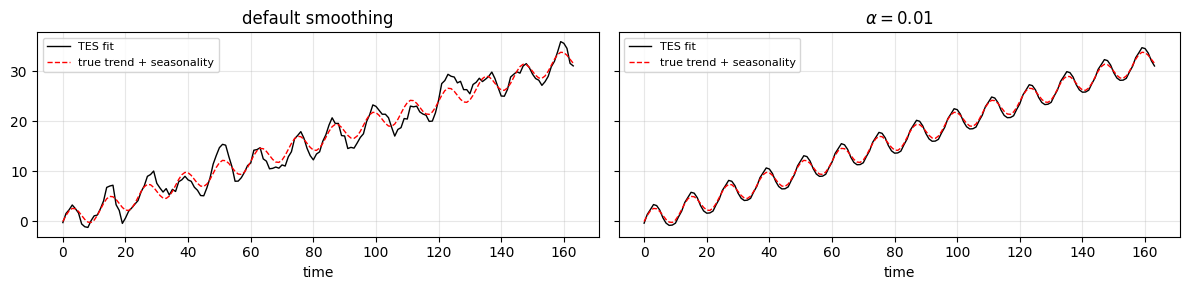

In [32]:
period, _, _ = fft_analysis(train_data_ma)
period = int(np.round(period))

tes_ma_default = ExponentialSmoothing(train_data_ma, trend="add",
                                      seasonal="add", seasonal_periods=period).fit()
tes_ma = ExponentialSmoothing(train_data_ma, trend="add",
                              seasonal="add", seasonal_periods=period).fit(smoothing_level=0.01)
trend_and_seasonality_default = tes_ma_default.fittedvalues
trend_and_seasonality = tes_ma.fittedvalues

print(f"default fit: alpha = {tes_ma_default.params['smoothing_level']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
for ax, fitted, name in [(axes[0], trend_and_seasonality_default, "default smoothing"),
                         (axes[1], trend_and_seasonality, r"$\alpha = 0.01$")]:
    ax.plot(time[:n_train], fitted, color="black", lw=1, label="TES fit")
    ax.plot(time[:n_train], trend[:n_train] + seasonality[:n_train], color="red", lw=1, ls="--",
            label="true trend + seasonality")
    ax.set(title=name, xlabel="time"); ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

With the default settings the optimizer picks $\alpha \approx 0.71$, and the fitted level chases the noise (left panel). This is not a bug. TES chooses its parameters by minimizing one-step-ahead errors, and the MA(2) noise is strongly autocorrelated ($\rho(1) \approx 0.6$), so following it *does* improve one-step predictions. But then part of the MA structure ends up in the "trend" and is removed from the residuals, leaving the MA model little to fit. The AR(2) noise has a weaker lag-1 correlation ($\approx 0.3$) and a negative lag-2 one; following it did not pay, and the optimizer chose $\alpha = 0$ on its own. Fixing $\alpha = 0.01$ makes the level nearly rigid, and the fit follows the true trend and seasonality closely (right panel).

We compute the residuals by subtracting the estimated trend and seasonality, and compare their ACF with that of the MA(2) component.

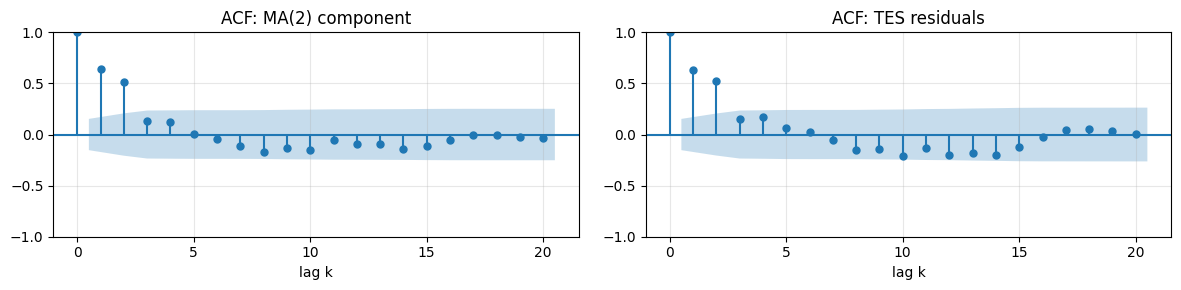

In [33]:
tes_resid_ma = train_data_ma - trend_and_seasonality

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
plot_acf(ma_data[:n_train], lags=20, ax=axes[0], title="ACF: MA(2) component")
plot_acf(tes_resid_ma, lags=20, ax=axes[1], title="ACF: TES residuals")
for ax in axes:
    ax.set_xlabel("lag k"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

The ACF of the TES residuals closely matches that of the MA(2) component: two significant lags, then a cut-off (lags 3 and 4 are inside the band). So $q = 2$, the true order.

> **Note.** The handbook reports a spike at lag 3 here and goes on to use MA(3). Its code, however, plots the ACF of the residuals of the *AR* example (`tes_resid`) instead of `tes_resid_ma`. With the right residuals, the ACF points to the order we simulated.

As in the AR case, we compute predictions with both the differencing and the TES-based approach.

### Predictions with the differencing approach

We fit an MA model to `diff_diff_ma` and forecast. Even though the data were generated by an MA(2) process, we use **MA(3)**: the differenced noise really is an MA(3) in its short lags, as shown above. (The lag-12 part would need a *seasonal* MA term, which is what seasonal ARIMA provides.)

[-0.    -0.078  0.076 -0.996  1.997]


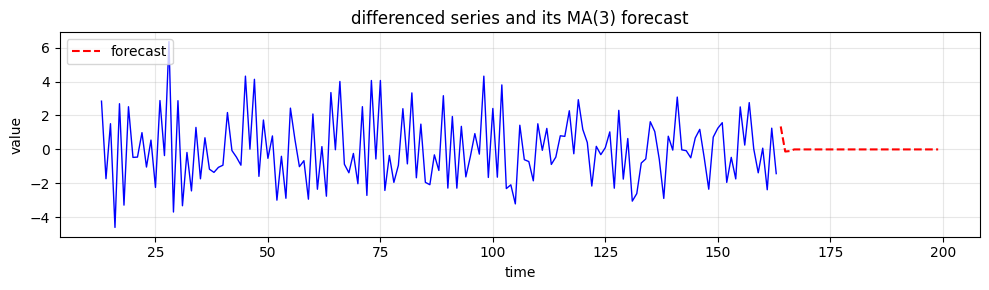

In [34]:
model = ARIMA(diff_diff_ma, order=(0, 0, 3))
model_fit = model.fit()
print(model_fit.params.round(3))

diff_preds = model_fit.forecast(steps=len(test_data_ma))

ax = run_sequence_plot(diff_diff_ma, t_dd, title="differenced series and its MA(3) forecast", figsize=(10, 3))
ax.plot(t_test, diff_preds, color="red", ls="--", lw=1.5, label="forecast")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Two things to notice.

- The fitted polynomial $1 - 0.08B + 0.08B^2 - 1.00B^3$ has coefficients that sum to almost exactly zero, so it has a root at $B = 1$: a **unit root in the MA part**. The true polynomial of the first-differenced noise, $1 - 0.3B + 0.1B^2 - 0.8B^3$, has the same property, as any polynomial multiplied by $(1 - B)$ must. A fitted MA polynomial with a root on the unit circle is the textbook sign that one difference too many has been taken.
- The MA forecast is even more short-sighted than the AR one: after $q = 3$ steps it is **exactly** the mean. Beyond $q$ steps ahead, every shock in the model equation lies in the future, and future shocks are forecast as zero.

We revert the two differencing operations to obtain the final predictions.

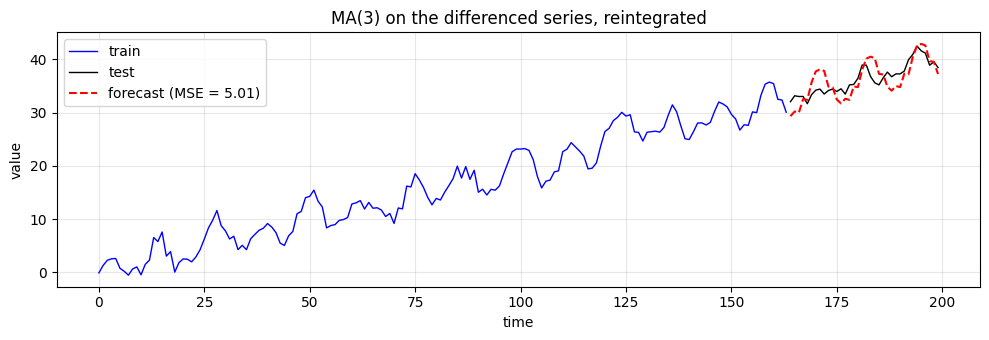

In [35]:
# Reintegrating the seasonal differencing
reintegrated_seasonal = np.zeros(len(test_data_ma))
reintegrated_seasonal[:12] = diff_ma[-12:] + diff_preds[:12]
for i in range(12, len(test_data_ma)):
    reintegrated_seasonal[i] = reintegrated_seasonal[i - 12] + diff_preds[i]

# Reintegrating the first-order differencing
reintegrated = reintegrated_seasonal.cumsum() + train_data_ma[-1]

forecast_plot(train_data_ma, test_data_ma, reintegrated, title="MA(3) on the differenced series, reintegrated")
plt.tight_layout(); plt.show()

### Predictions with the TES-based approach

This time we fit the MA model to `tes_resid_ma` and forecast. We use **MA(2)**, the order that the ACF of the TES residuals pointed to.

[-0.005  0.796  0.876  0.907]


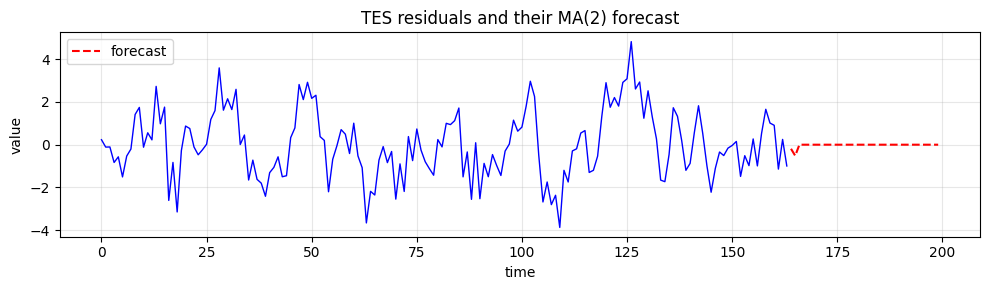

In [36]:
model = ARIMA(tes_resid_ma, order=(0, 0, 2))
model_fit = model.fit()
print(model_fit.params.round(3))

resid_preds = model_fit.forecast(steps=len(test_data_ma))

ax = run_sequence_plot(tes_resid_ma, time[:n_train], title="TES residuals and their MA(2) forecast", figsize=(10, 3))
ax.plot(t_test, resid_preds, color="red", ls="--", lw=1.5, label="forecast")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

The final predictions combine

- the MA model's forecast of the residuals, and
- TES's forecast of the trend and seasonality.

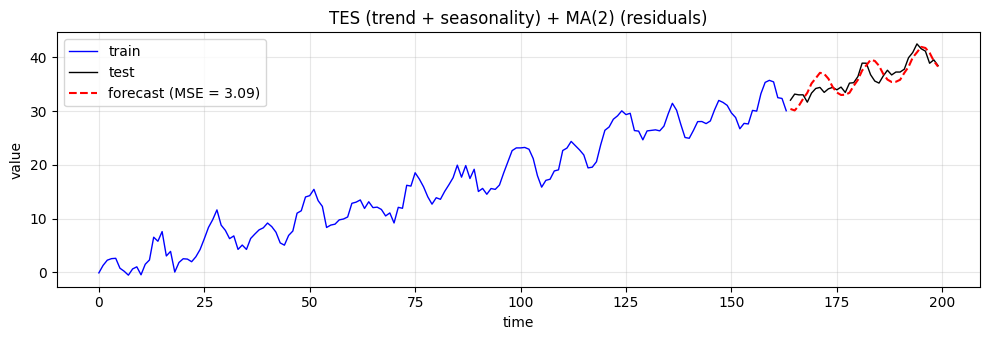

In [37]:
# Add back trend and seasonality to the predictions
tes_pred = tes_ma.forecast(len(test_data_ma))
final_preds = tes_pred + resid_preds

forecast_plot(train_data_ma, test_data_ma, final_preds, title="TES (trend + seasonality) + MA(2) (residuals)")
plt.tight_layout(); plt.show()

Finally, the test-set MSE of the two approaches, with the same two references as before.

In [38]:
score_table(test_data_ma, {
    "differencing + MA(3)":             reintegrated,
    "TES + MA(2)":                      final_preds,
    "TES alone":                        tes_pred,
    "oracle: true trend + seasonality": trend[n_train:] + seasonality[n_train:],
})

                                     MSE, all 36 steps    MSE, first 3 steps
differencing + MA(3)                              5.01                  8.40
TES + MA(2)                                       3.09                  5.33
TES alone                                         3.00                  4.16
oracle: true trend + seasonality                  2.01                  2.67


- As in the AR case, the **TES-based approach beats differencing** (3.09 vs 5.01), for the same reason: seasonal reintegration copies last season's noise forward.
- This time the MA model **does not help even in the first steps**: TES alone is better over the first three (4.16 vs 5.33). An MA(2) can change only the first two forecasts; after that it forecasts exactly the mean. In this sample, the shocks that followed the end of the training data went the other way.

Two forecasts are far too few to judge a model by. On average, the same $\psi$-weight argument as for AR gives the MA(2) an error variance of $\sigma^2 = 1$ at $h = 1$ and $1 + \theta_1^2 = 1.49$ at $h = 2$, against $\mathrm{Var}(x_t) = 1 + \theta_1^2 + \theta_2^2 = 2.13$ for the mean; from $h = 3$ on it adds nothing. A fair evaluation uses many forecast origins, not one. *Rolling-origin* evaluation (time-series cross-validation) repeats the forecast from every point of the test period.

---

# Summary

## AR vs MA models

| | **AR($p$) models** | **MA($q$) models** |
|:--|:--|:--|
| Depend on | past **values** of the series | past forecast **errors** (shocks) |
| A shock... | decays geometrically, never fully forgotten | is forgotten after exactly $q$ steps |
| **ACF** | tails off (geometric decay or damped oscillation) | **cuts off after lag $q$** |
| **PACF** | **cuts off after lag $p$** | tails off |
| Stationarity | only for some $\phi$ (roots outside the unit circle) | always |
| Estimation | least squares on lags is enough | iterative, nonlinear (shocks are unobserved) |
| Long-horizon forecast | reverts to the mean geometrically | equals the mean after $q$ steps |
| Suited to | slowly changing series, where past values directly drive future ones | series explained by short-lived shocks or random disturbances, i.e., series with sudden changes |

In this lecture we learned:

1. Both models need **stationary** data. To forecast a series with trend and seasonality: make it stationary, fit AR/MA to what is left, forecast, then **reconstruct**. The reconstruction either undoes the differencing, or adds back the trend and seasonality predicted by a smoother.
2. Differencing is a filter, and it leaves fingerprints: the first difference of an MA($q$) is an MA($q+1$), and a seasonal difference of a deterministic season puts a spike of about $-0.5$ at lag $L$. That is **over-differencing**, and it makes the correlograms harder to read.
3. Stationary AR and MA forecasts revert to the mean after a few steps. Long-horizon skill comes from the trend and seasonality, not from the AR/MA part.
4. **Moving-average** models write the series as a weighted sum of recent shocks. Choose the order $q$ as the last significant lag of the **ACF**.
5. Mind the `statsmodels` convention: `ar = [1, -phi_1, ..., -phi_p]`, `ma = [1, theta_1, ..., theta_q]`.

**Next.** ARMA models combine the two parts. ARIMA adds the differencing to the model, so the reintegration bookkeeping is done for us; seasonal ARIMA adds seasonal AR and MA terms for the lag-$L$ structure that we could not model here.